In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240507_TS_C10_W3_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240507_TS_C10_W3_run2.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling1')

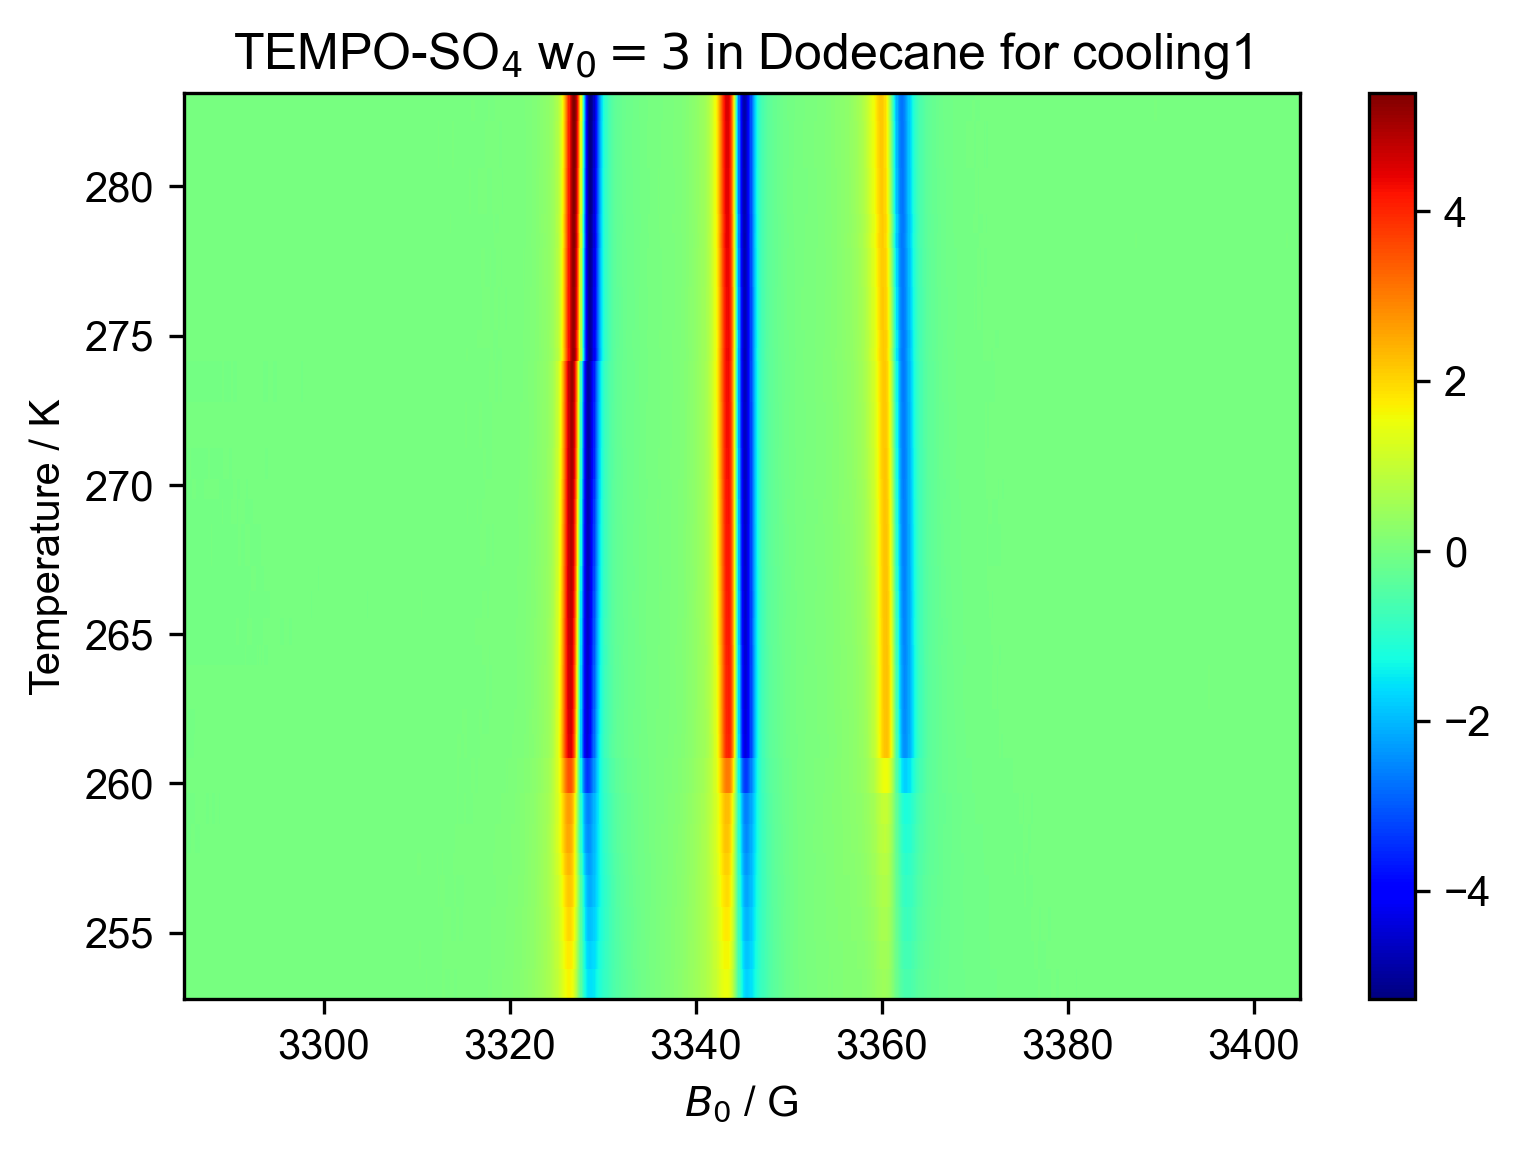

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling1")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in Dodecane for heating1')

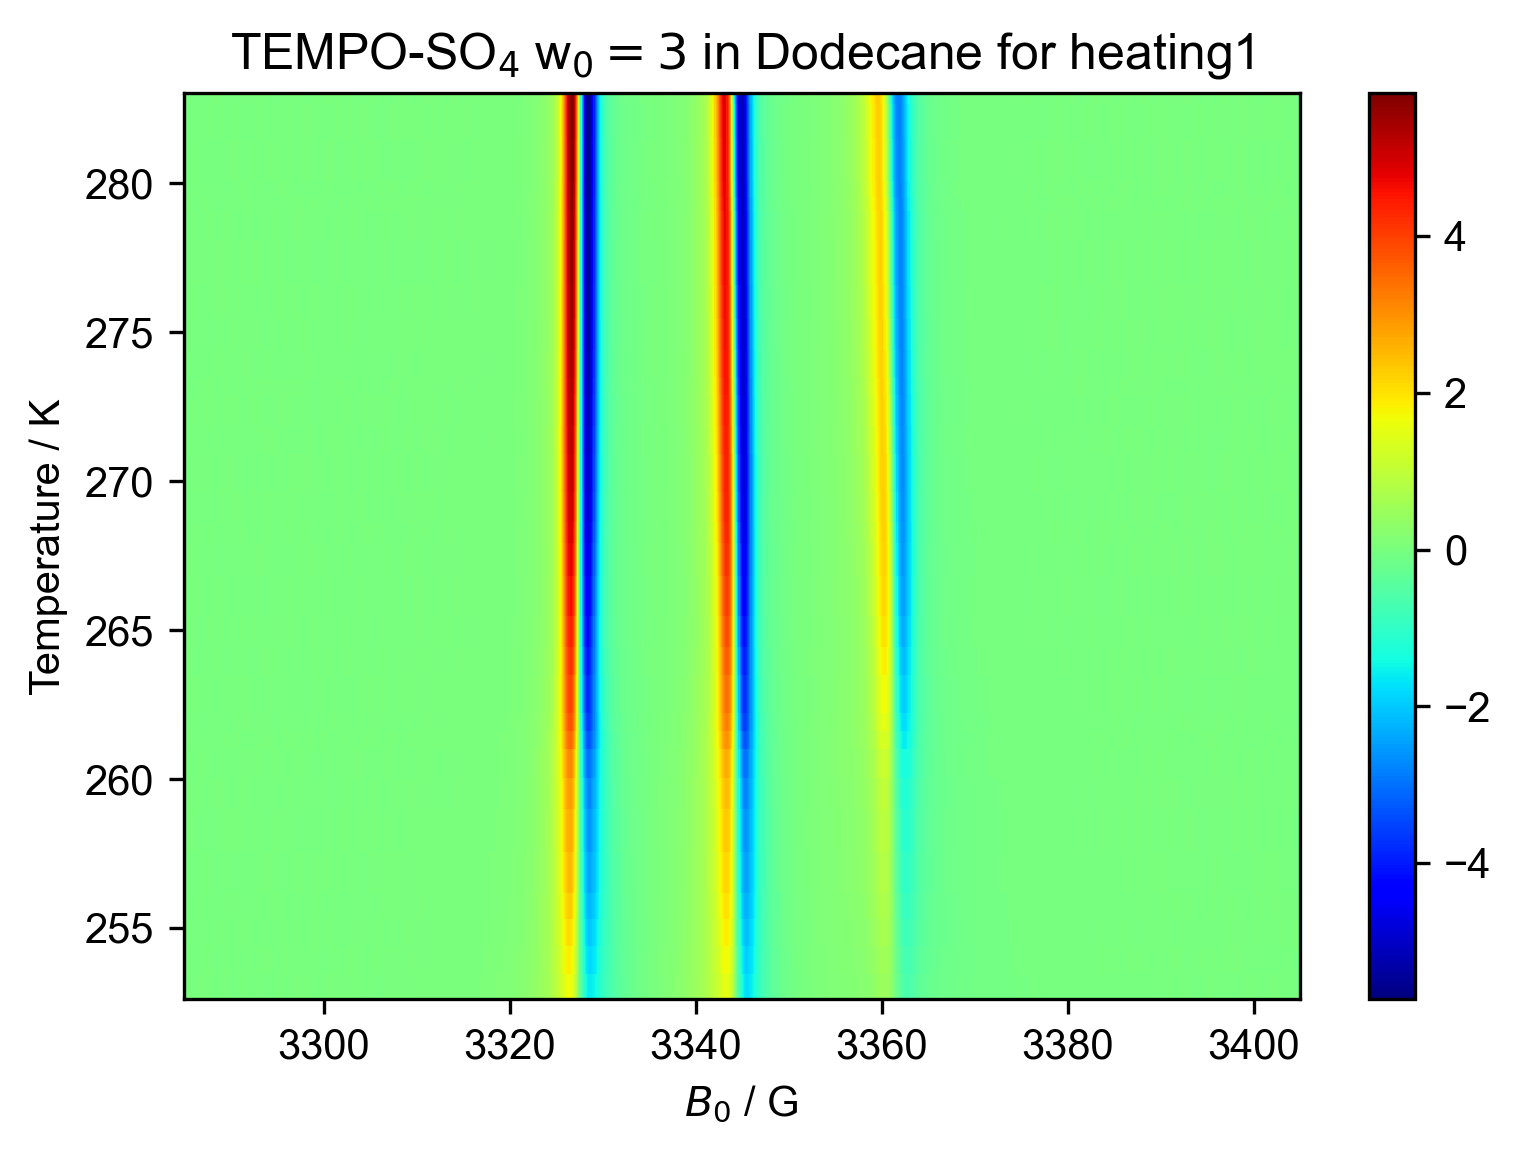

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for heating1")

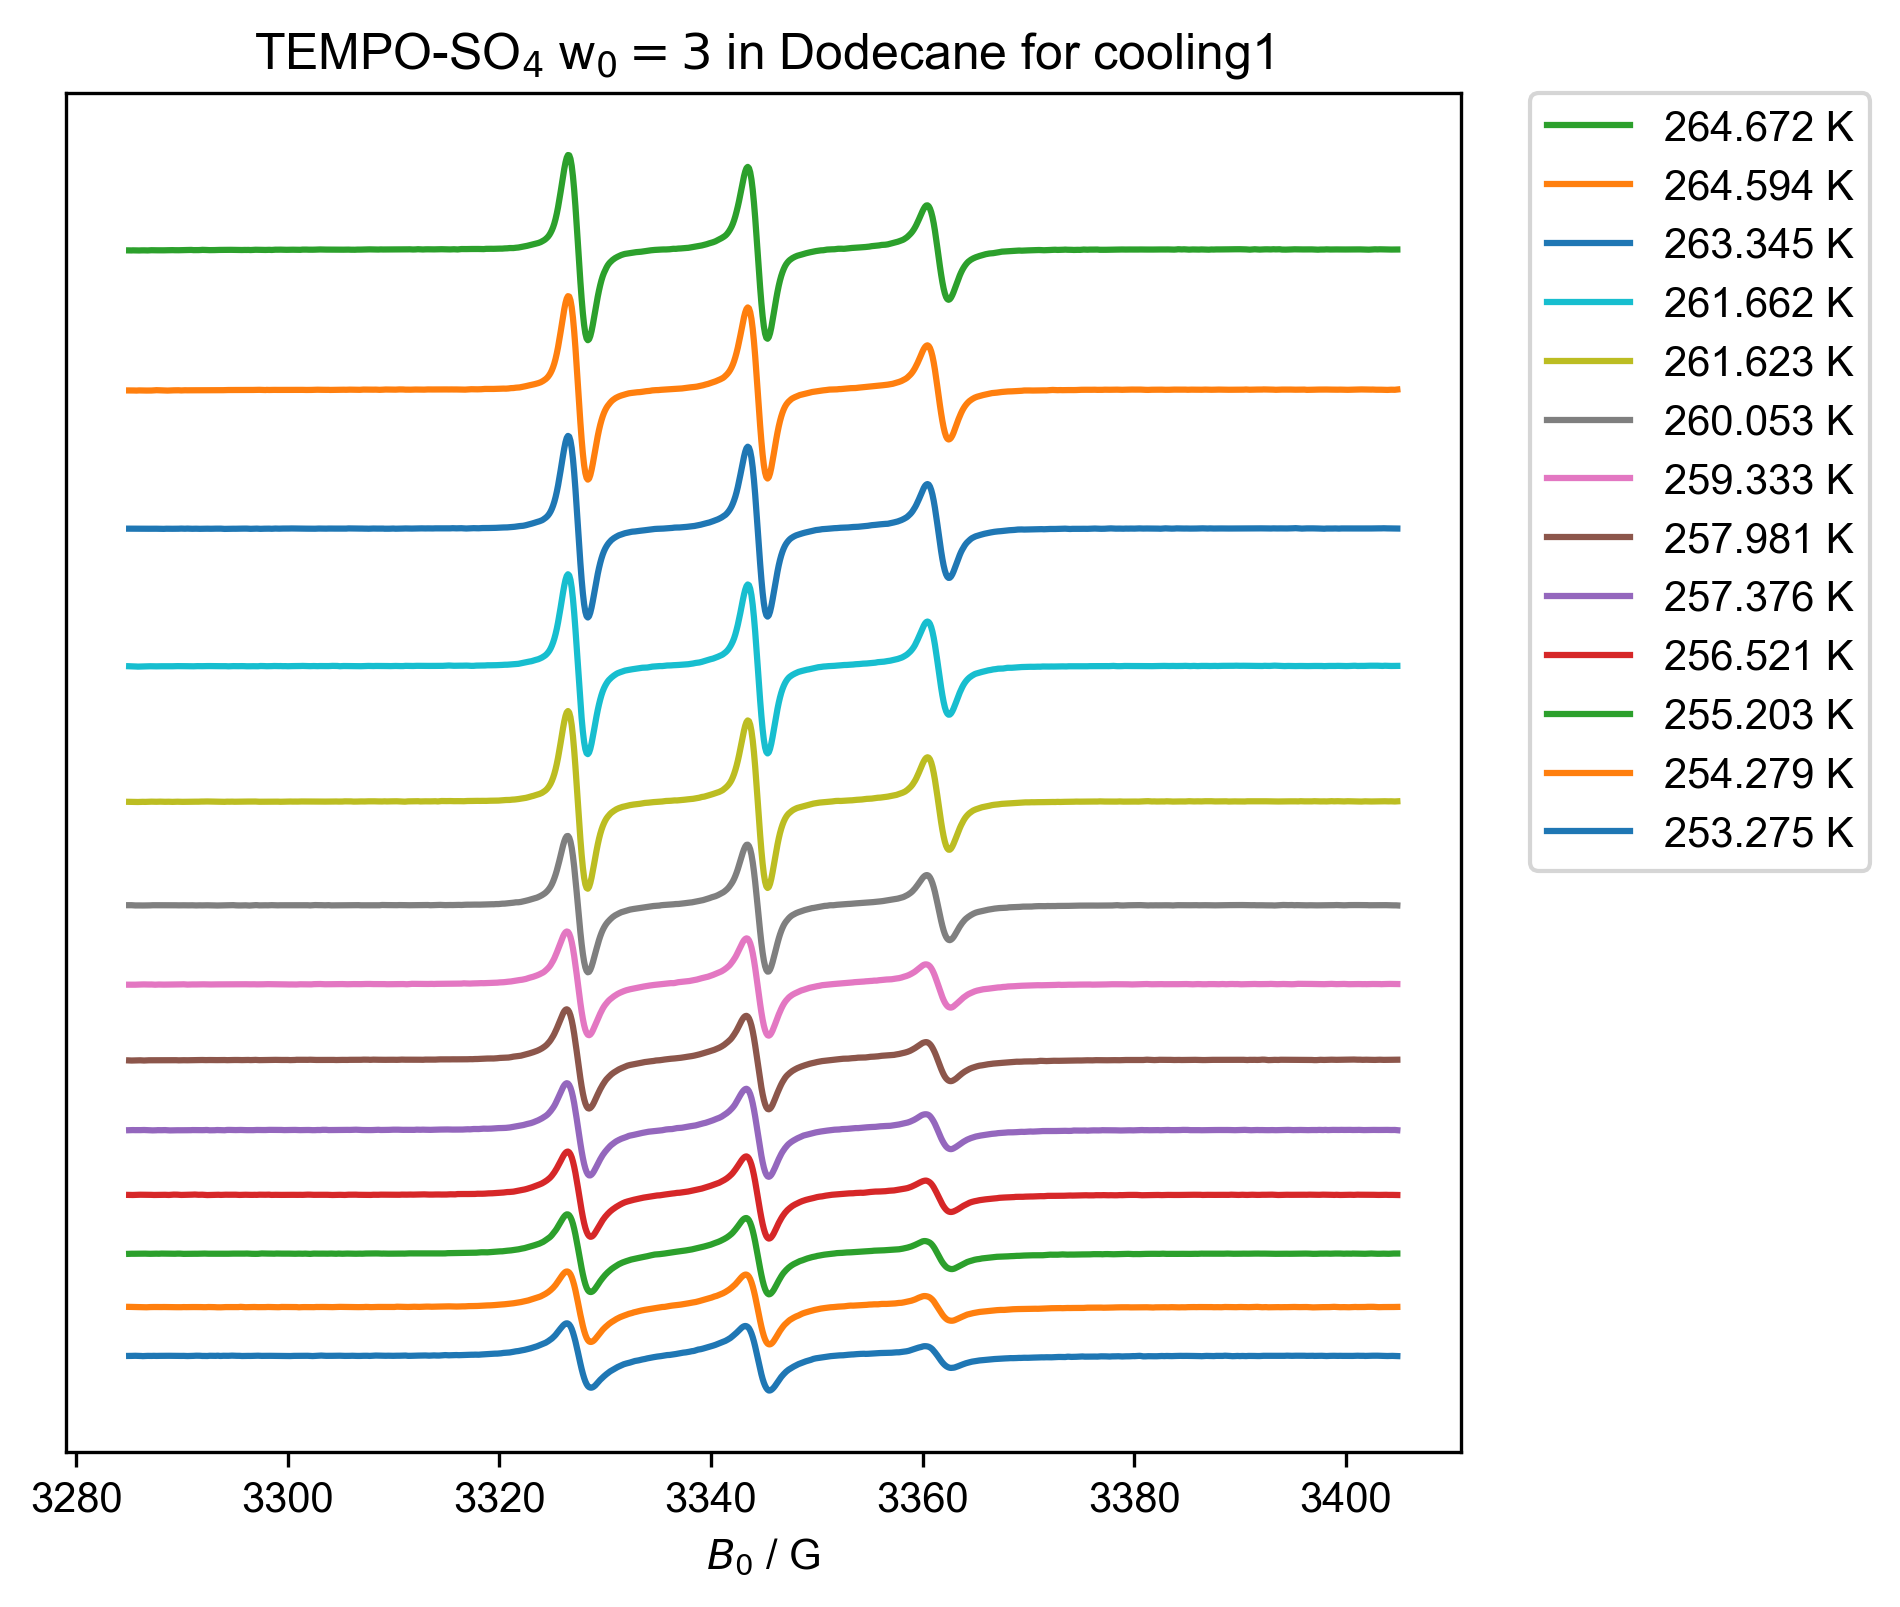

In [23]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling1", (250, 265))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

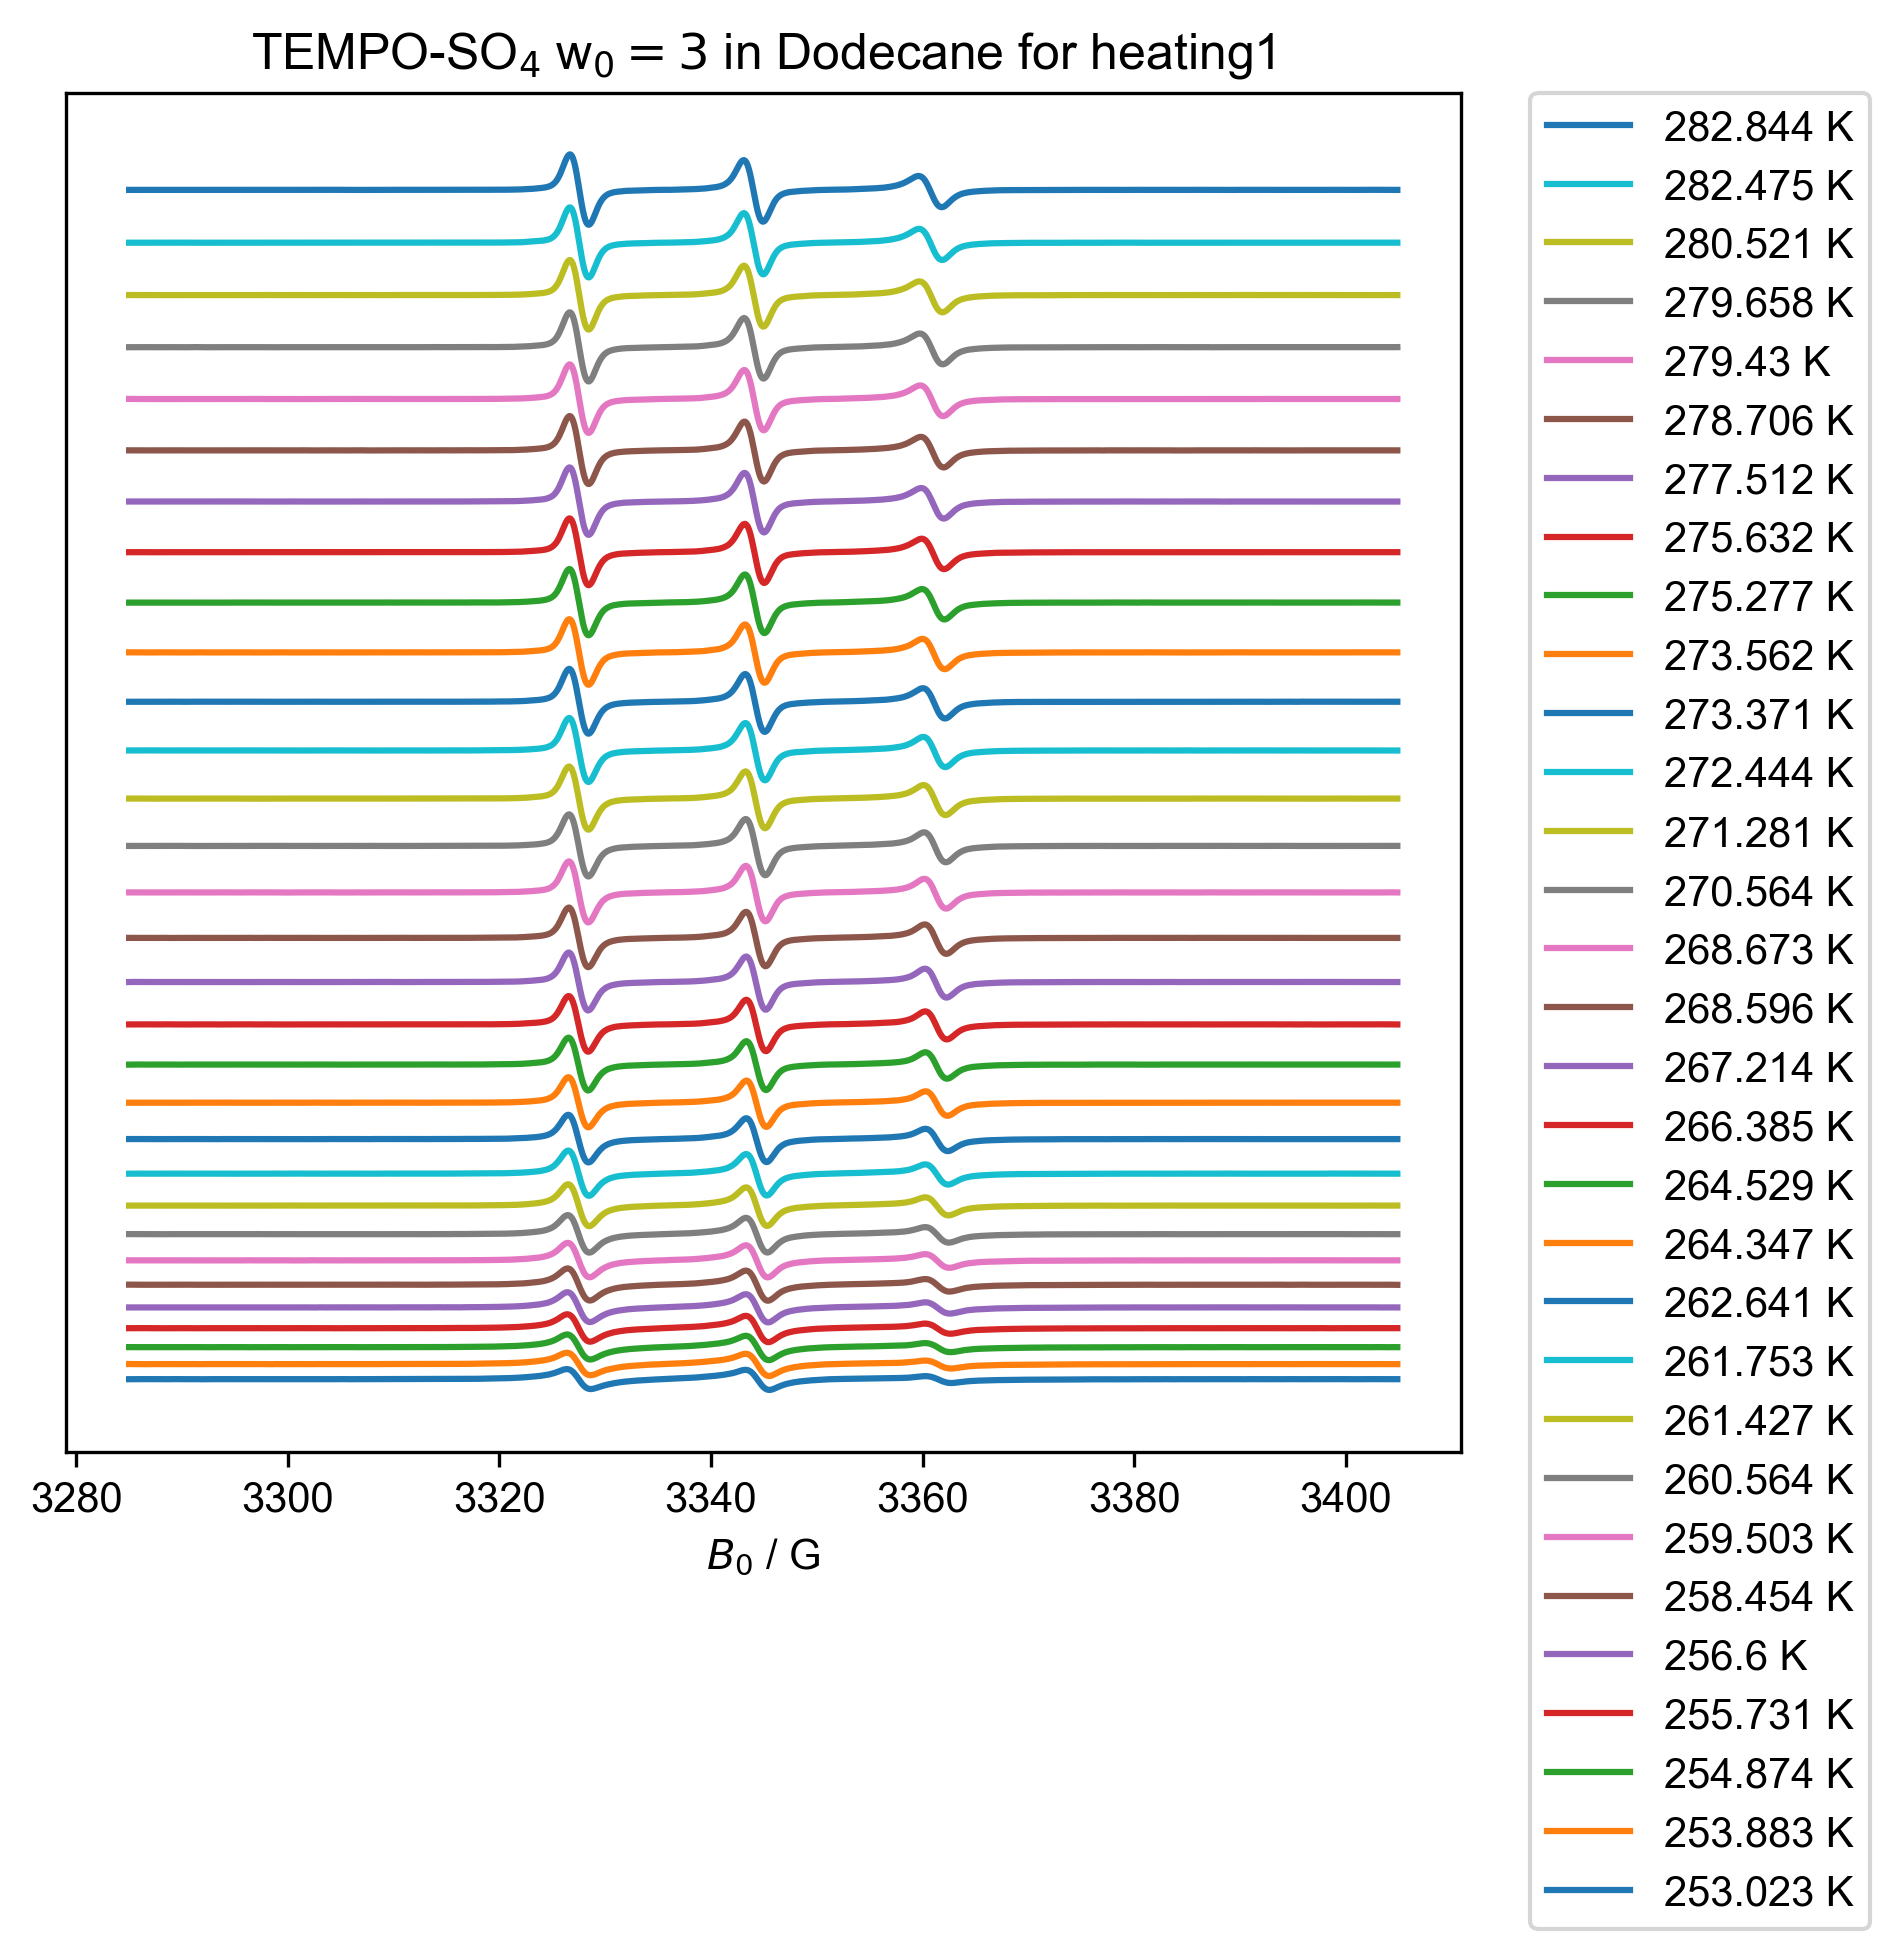

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=3$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[253.275 254.279 255.203 256.521 257.376 257.981 259.333 260.053 261.623
 261.662 263.345 264.594 264.672 266.398 266.515 268.028 269.343 269.678
 270.743 271.755 273.816 274.502 274.667 275.721 277.512 278.349 278.552
 279.594 281.611 282.791 283.006]
[253.023 253.883 254.874 255.731 256.6   258.454 259.503 260.564 261.427
 261.753 262.641 264.347 264.529 266.385 267.214 268.596 268.673 270.564
 271.281 272.444 273.371 273.562 275.277 275.632 277.512 278.706 279.43
 279.658 280.521 282.475 282.844]


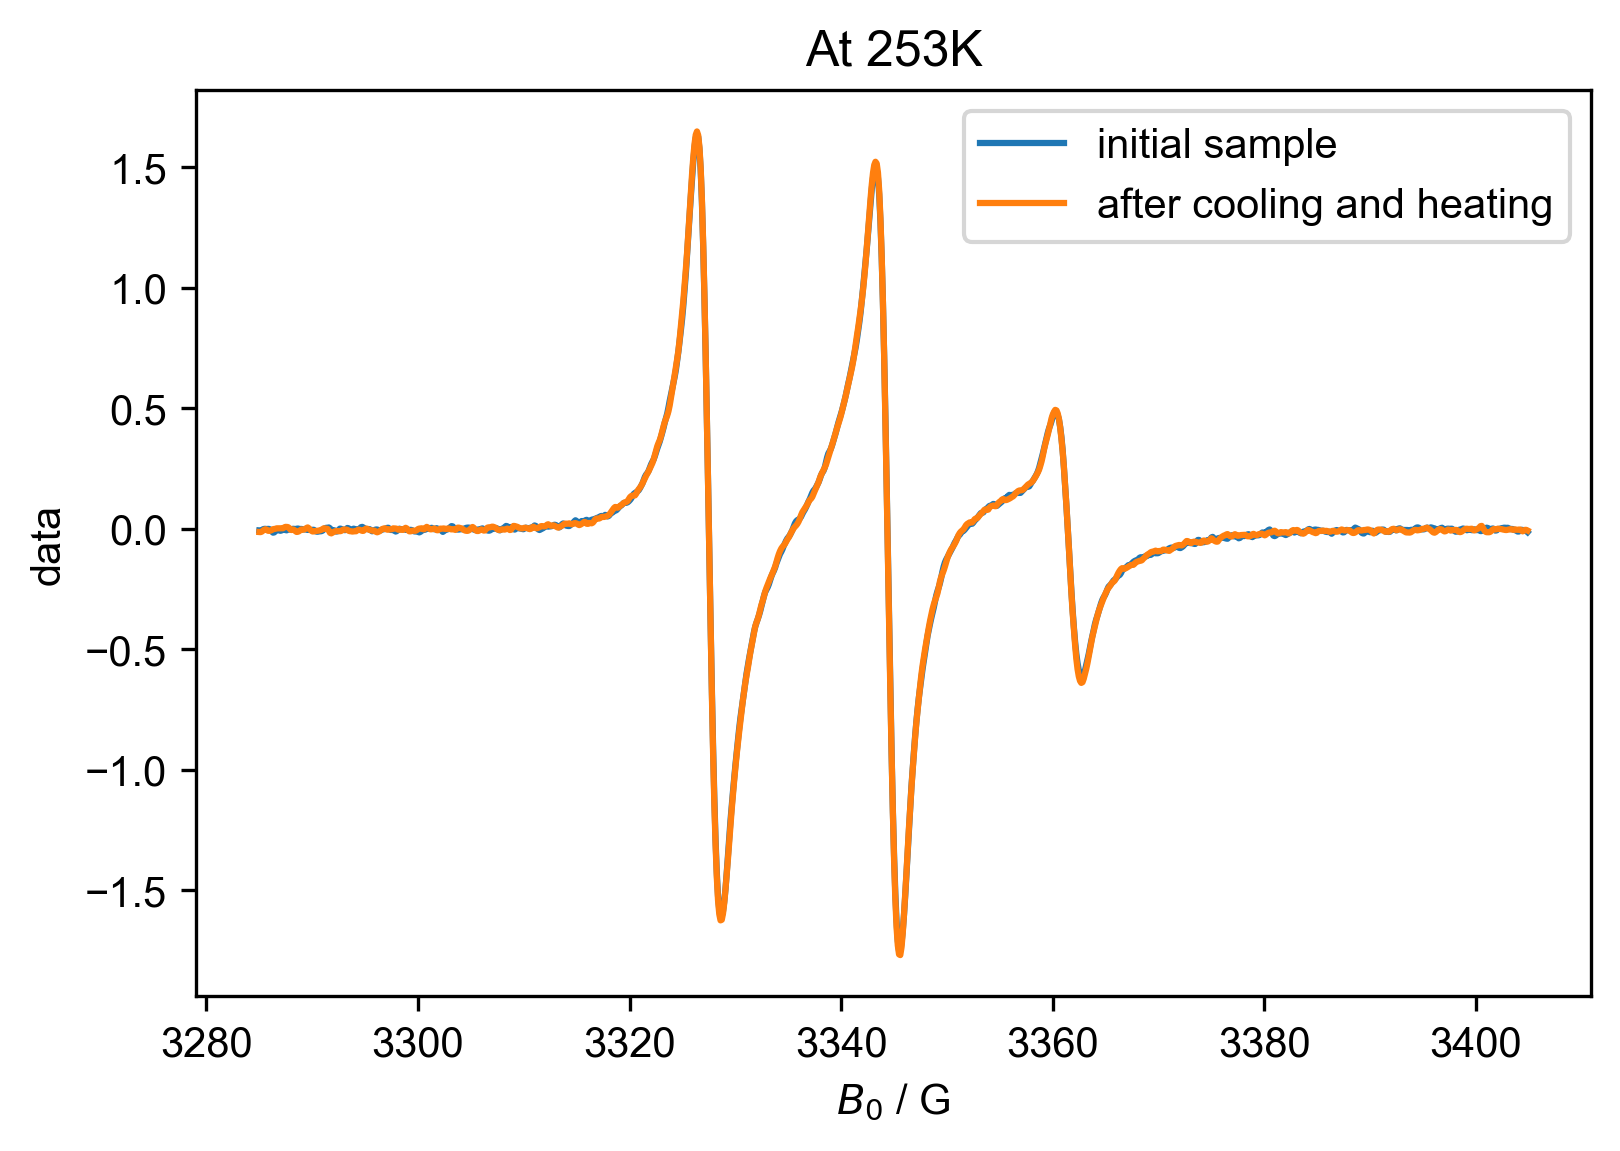

In [22]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

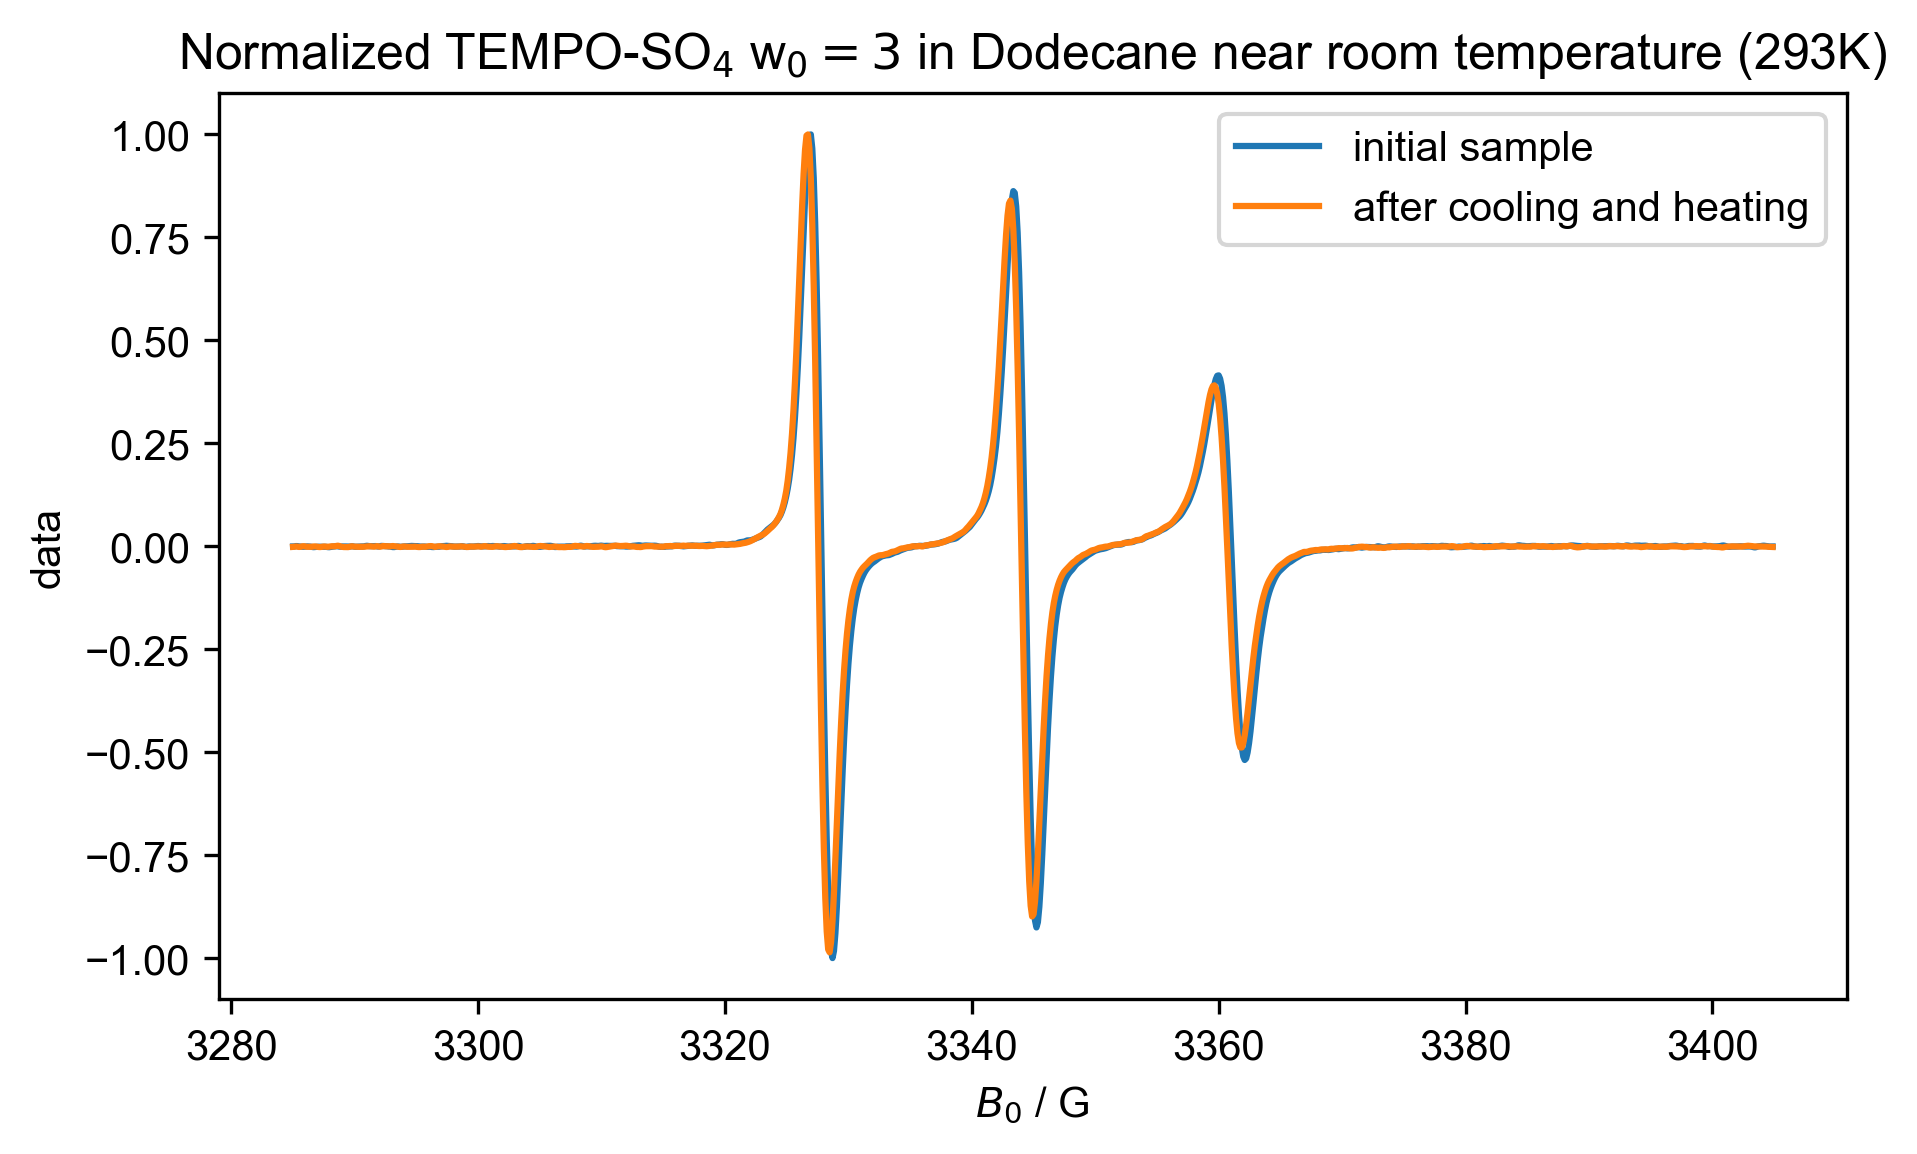

In [12]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "initial sample")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 3$ in Dodecane near room temperature (293K)")
legend()